<a href="https://colab.research.google.com/github/BenjaminBanansos/Agmdc-app/blob/main/Housing_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import sklearn

In [ ]:
data = pd.read_csv('housing.csv')

In [ ]:
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [ ]:
data.columns


Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [ ]:
+9*data.shape

(20640,
 10,
 20640,
 10,
 20640,
 10,
 20640,
 10,
 20640,
 10,
 20640,
 10,
 20640,
 10,
 20640,
 10,
 20640,
 10)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
data.dropna(inplace=True)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x = data.drop(['median_house_value'],axis = 1)
y = data ['median_house_value']

In [ ]:
x

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY
...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,INLAND


In [ ]:
y


0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 20433, dtype: float64

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)

In [ ]:
train_data = x_train.join(y_train)

In [ ]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
2702,-115.57,32.85,17.0,1039.0,256.0,728.0,246.0,1.7411,INLAND,63500.0
15136,-116.92,32.84,16.0,4675.0,834.0,2188.0,817.0,4.6674,<1H OCEAN,178000.0
13956,-117.06,34.17,21.0,2520.0,582.0,416.0,151.0,2.7120,INLAND,89000.0
12640,-121.45,38.53,34.0,1893.0,415.0,884.0,395.0,2.1679,INLAND,75400.0
19206,-122.72,38.47,29.0,1706.0,415.0,990.0,394.0,1.9932,<1H OCEAN,164800.0
...,...,...,...,...,...,...,...,...,...,...
11282,-117.95,33.78,26.0,4115.0,883.0,2184.0,825.0,3.9536,<1H OCEAN,191000.0
13480,-117.37,34.10,44.0,2087.0,447.0,1270.0,423.0,2.3889,INLAND,86100.0
4661,-118.30,34.05,44.0,1612.0,650.0,2028.0,593.0,1.9152,<1H OCEAN,115600.0
5840,-118.32,34.19,37.0,1335.0,249.0,485.0,240.0,4.1731,<1H OCEAN,352100.0


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

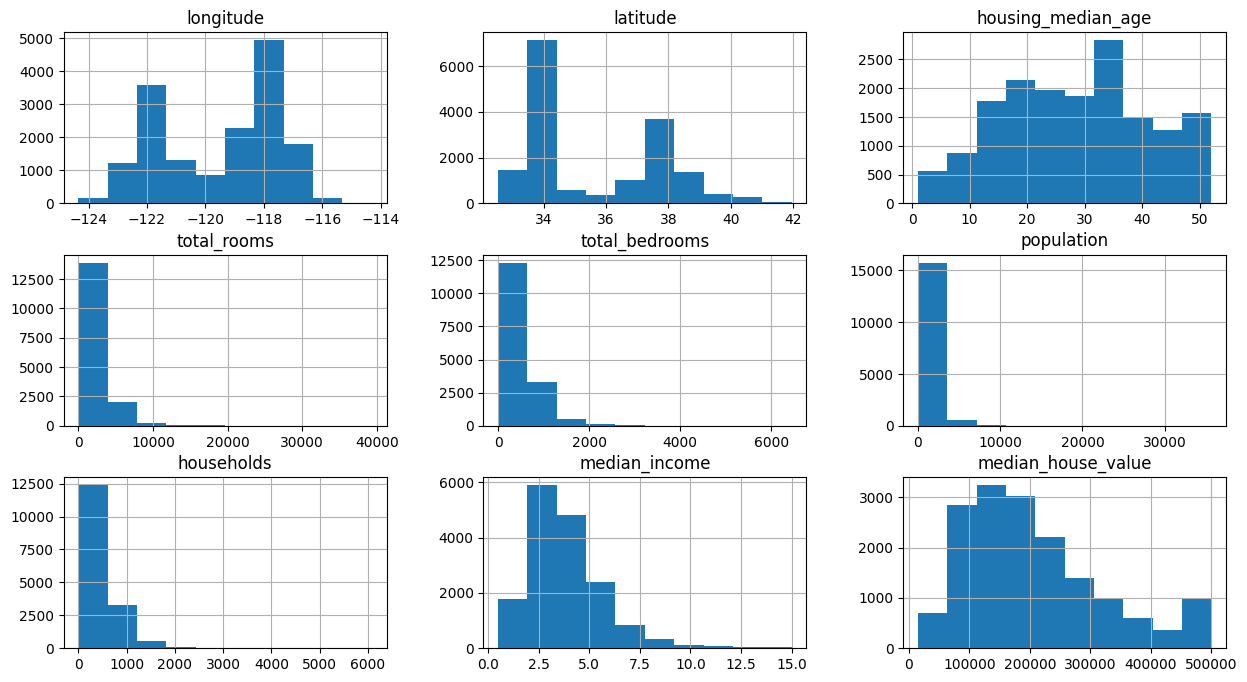

In [ ]:
train_data.hist(figsize=(15,8))

In [ ]:
 train_data.corr()

<ipython-input-21-8d2cc80a8830>:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  train_data.corr()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924719,-0.112824,0.046226,0.069757,0.101155,0.056783,-0.012379,-0.043091
latitude,-0.924719,1.000000,0.013540,-0.037200,-0.066604,-0.110053,-0.072318,-0.083818,-0.146591
housing_median_age,-0.112824,0.013540,1.000000,-0.356139,-0.316246,-0.290807,-0.297456,-0.113998,0.109927
total_rooms,0.046226,-0.037200,-0.356139,1.000000,0.928980,0.853524,0.917918,0.193965,0.132116
total_bedrooms,0.069757,-0.066604,-0.316246,0.928980,1.000000,0.873906,0.979362,-0.013741,0.044161
population,0.101155,-0.110053,-0.290807,0.853524,0.873906,1.000000,0.903957,-0.003654,-0.030866
households,0.056783,-0.072318,-0.297456,0.917918,0.979362,0.903957,1.000000,0.007477,0.059623
median_income,-0.012379,-0.083818,-0.113998,0.193965,-0.013741,-0.003654,0.007477,1.000000,0.694005
median_house_value,-0.043091,-0.146591,0.109927,0.132116,0.044161,-0.030866,0.059623,0.694005,1.000000


<ipython-input-22-369badec8687>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(train_data.corr(), annot= True,cmap="YlGnBu")


<Axes: >

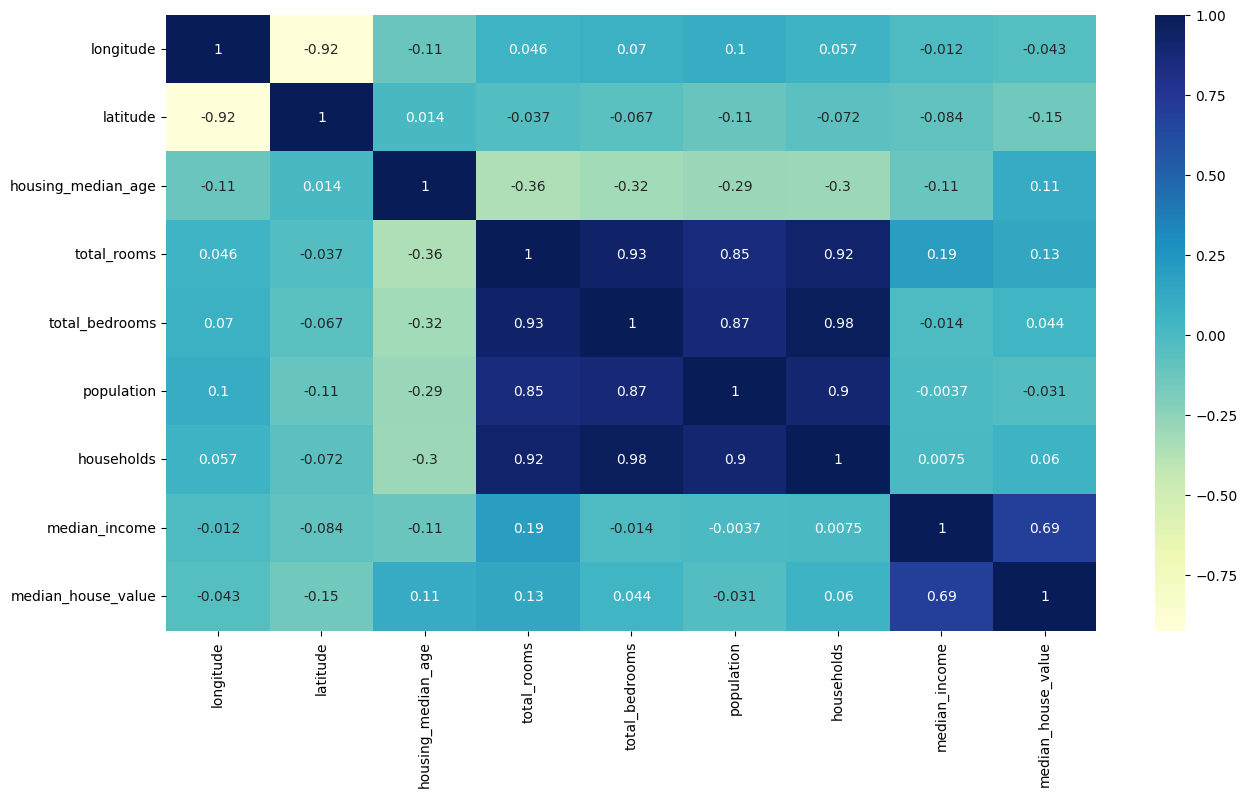

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(), annot= True,cmap="YlGnBu")

In [ ]:
train_data['total_rooms']=np.log(train_data['total_rooms']+1)
train_data['total_bedrooms']=np.log(train_data['total_bedrooms']+1)
train_data['population']=np.log(train_data['population']+1)
train_data['households']=np.log(train_data['households']+1)

train_data['ocean_proximity']

# scaler = StandardScaler()
# scaler.fit(train_data)

2702        INLAND
15136    <1H OCEAN
13956       INLAND
12640       INLAND
19206    <1H OCEAN
           ...    
11282    <1H OCEAN
13480       INLAND
4661     <1H OCEAN
5840     <1H OCEAN
8350     <1H OCEAN
Name: ocean_proximity, Length: 16346, dtype: object

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

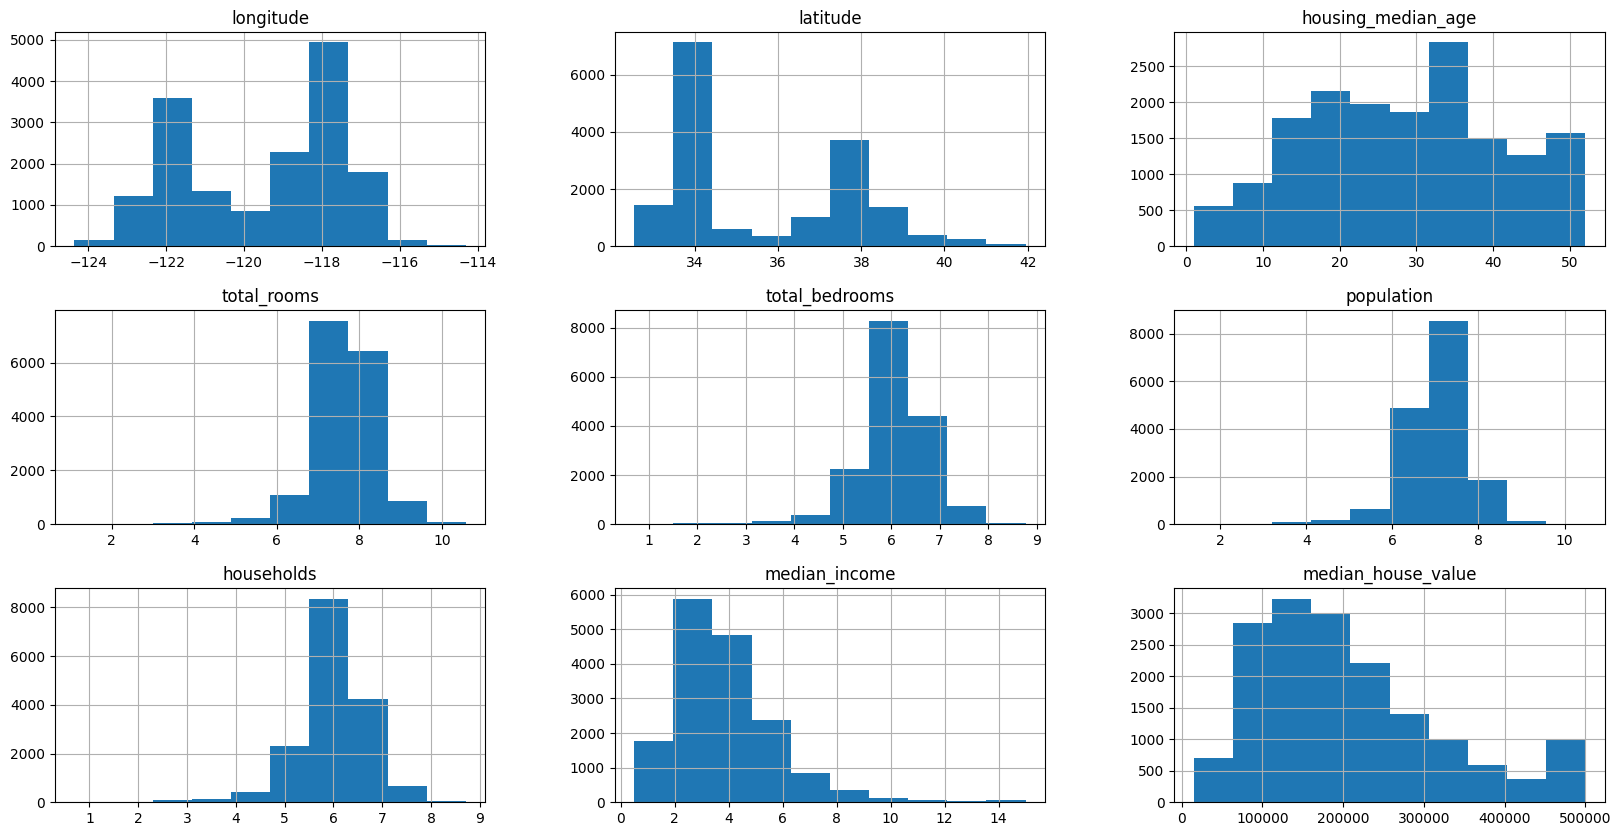

In [ ]:
train_data.hist(figsize=(20,10))

In [ ]:
train_data['ocean_proximity']
train_data.ocean_proximity.value_counts()


<1H OCEAN     7199
INLAND        5215
NEAR OCEAN    2119
NEAR BAY      1809
ISLAND           4
Name: ocean_proximity, dtype: int64

In [ ]:
train_data = train_data.join(pd.get_dummies(train_data.ocean_proximity)).drop(['ocean_proximity'],axis=1)

In [ ]:
 train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
2702,-115.57,32.85,17.0,6.946976,5.549076,6.591674,5.509388,1.7411,63500.0,0,1,0,0,0
15136,-116.92,32.84,16.0,8.450198,6.727432,7.691200,6.706862,4.6674,178000.0,1,0,0,0,0
13956,-117.06,34.17,21.0,7.832411,6.368187,6.033086,5.023881,2.7120,89000.0,0,1,0,0,0
12640,-121.45,38.53,34.0,7.546446,6.030685,6.785588,5.981414,2.1679,75400.0,0,1,0,0,0
19206,-122.72,38.47,29.0,7.442493,6.030685,6.898715,5.978886,1.9932,164800.0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11282,-117.95,33.78,26.0,8.322637,6.784457,7.689371,6.716595,3.9536,191000.0,1,0,0,0,0
13480,-117.37,34.10,44.0,7.643962,6.104793,7.147559,6.049733,2.3889,86100.0,0,1,0,0,0
4661,-118.30,34.05,44.0,7.385851,6.478510,7.615298,6.386879,1.9152,115600.0,1,0,0,0,0
5840,-118.32,34.19,37.0,7.197435,5.521461,6.186209,5.484797,4.1731,352100.0,1,0,0,0,0


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


from matplotlib import pyplot as plt
_df_0['index'].plot(kind='hist', bins=20, title='index')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['longitude'].plot(kind='hist', bins=20, title='longitude')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['latitude'].plot(kind='hist', bins=20, title='latitude')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['housing_median_age'].plot(kind='hist', bins=20, title='housing_median_age')
plt.gca().spines[['top', 'right',]].set_visible(False)

... (4 outputs left out)

from matplotlib import pyplot as plt
_df_8['index'].plot(kind='line', figsize=(8, 4), title='index')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_9['longitude'].plot(kind='line', figsize=(8, 4), title='longitude')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_10['latitude'].plot(kind='line', figsize=(8, 4), title='latitude')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_11['housing_median_age'].plot(kind='line', figsize=(8, 4), title='housing_median_age')
plt.gca().spines[['top', 'right']].set_visible(False)

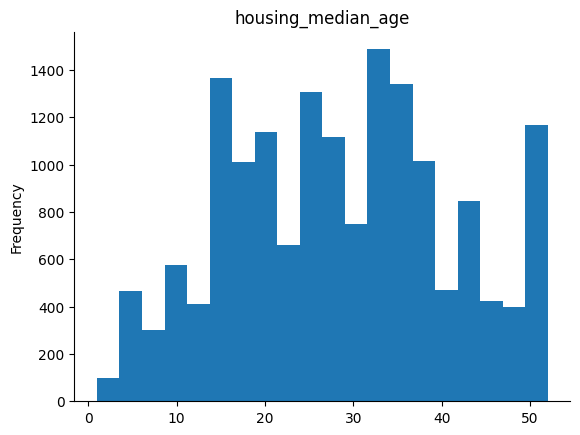

In [ ]:
from matplotlib import pyplot as plt
_df_3['housing_median_age'].plot(kind='hist', bins=20, title='housing_median_age')
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
train_data.shape
#test_data.shape

(16346, 14)

<Axes: >

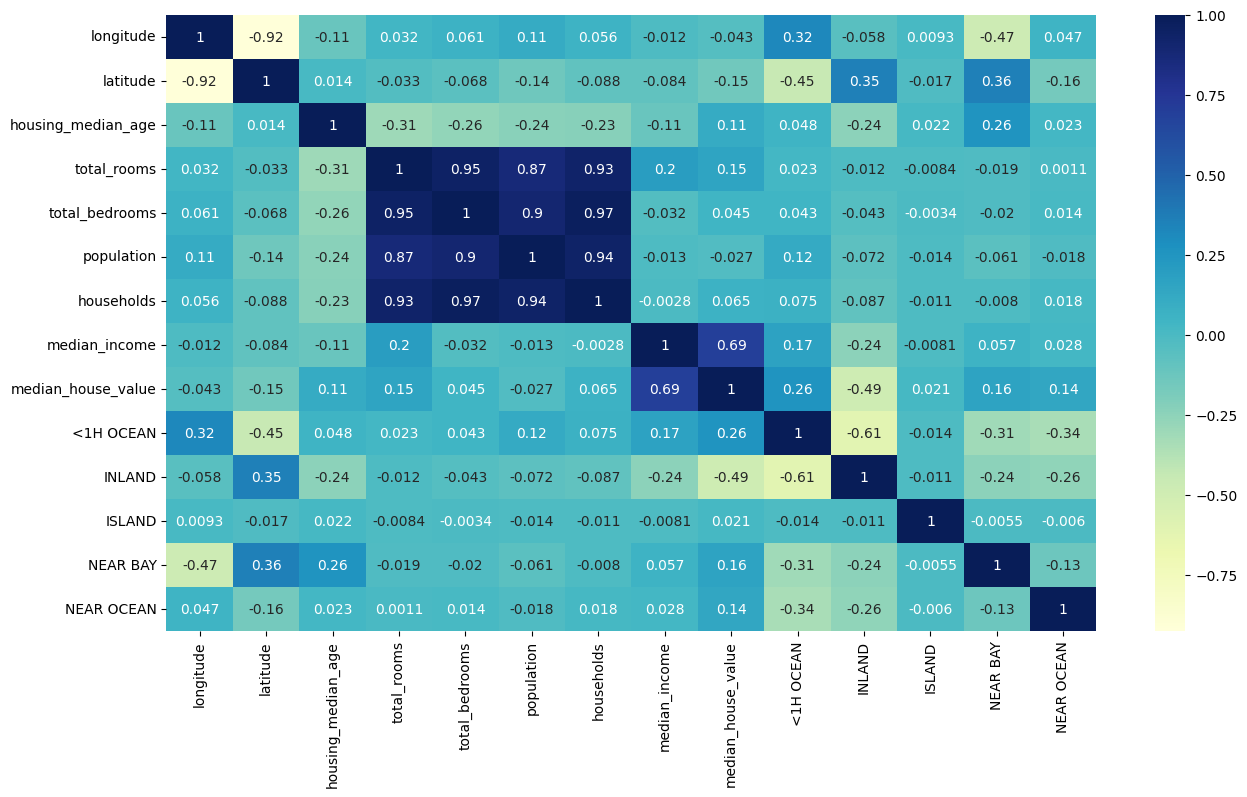

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(), annot= True,cmap="YlGnBu")

<Axes: xlabel='latitude', ylabel='longitude'>

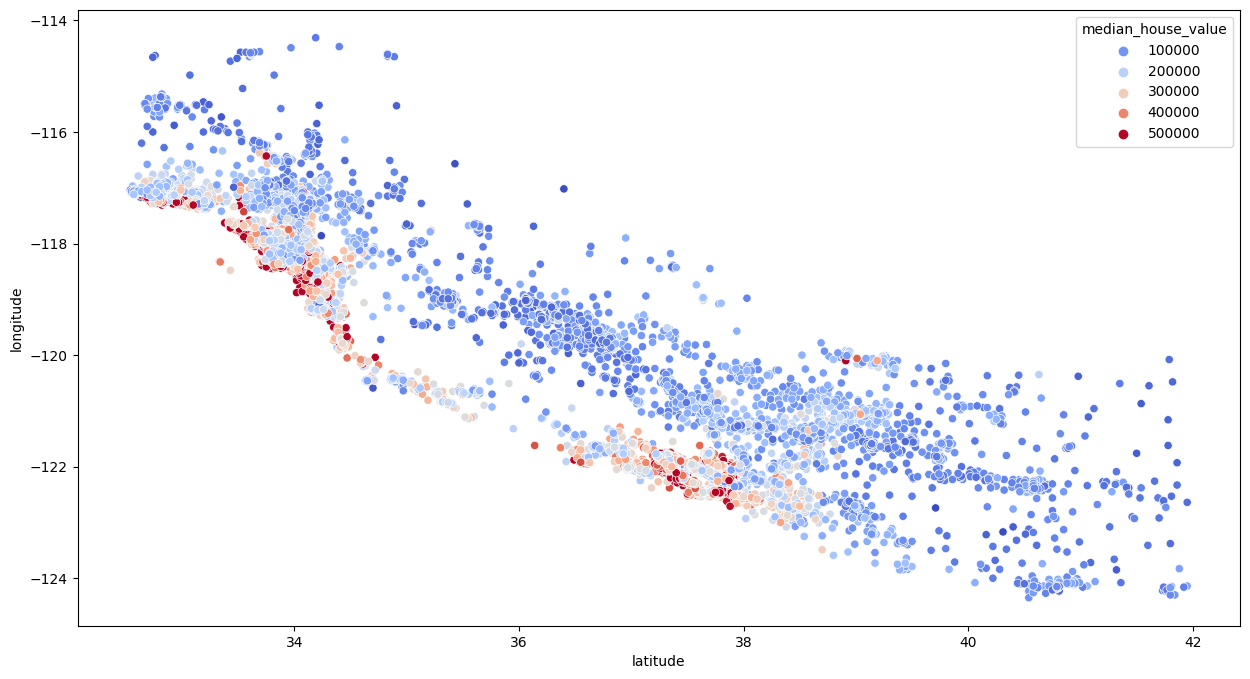

In [ ]:
plt.figure(figsize=(15,8))
sns.scatterplot(x='latitude',y='longitude',data = train_data,hue = 'median_house_value',palette='coolwarm')

In [ ]:
train_data['bedroom_ratio'] = train_data['total_bedrooms']/train_data['total_rooms']
train_data['household_rooms'] = train_data['total_rooms']/train_data['households']


<Axes: >

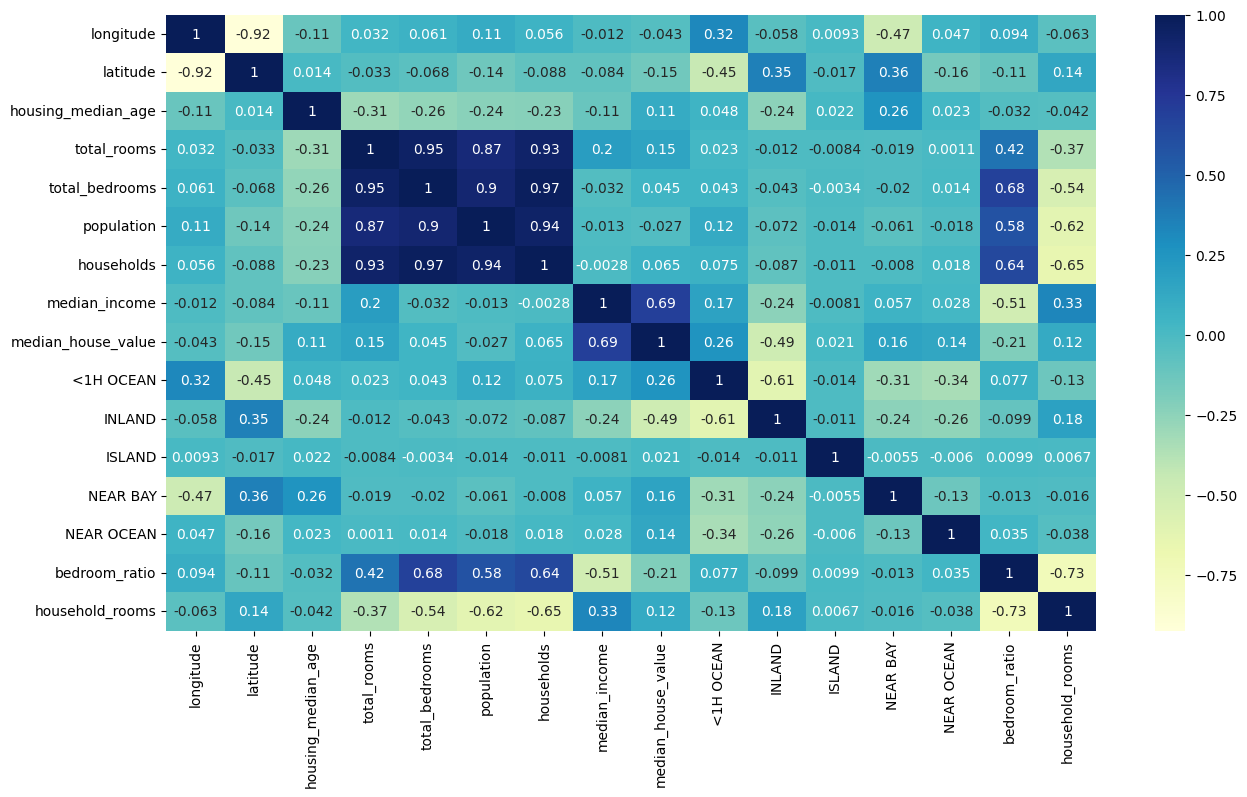

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(), annot= True,cmap="YlGnBu")

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train,y_train = train_data.drop(['median_house_value'],axis=1),train_data['median_house_value']
x_train_s = scaler.fit_transform(x_train)

reg = LinearRegression()
reg.fit(x_train_s, y_train)

LinearRegression()

In [ ]:
import sklearn
print(sklearn.__version__)


1.2.2


In [ ]:
x_train_s

array([[ 1.99172494, -1.29743164, -0.92468568, ..., -0.38310027,
         0.1879438 , -0.25745945],
       [ 1.3175101 , -1.30210593, -1.00415671, ..., -0.38310027,
         0.11631209, -0.26981946],
       [ 1.24759153, -0.68042568, -0.60680158, ..., -0.38310027,
         0.57413645,  3.42341335],
       ...,
       [ 0.62831271, -0.73651713,  1.221032  , ..., -0.38310027,
         2.30755255, -1.54809256],
       [ 0.61832434, -0.67107711,  0.66473482, ..., -0.38310027,
        -0.6675447 ,  0.37619687],
       [ 0.61832434, -0.77858572,  1.45944507, ..., -0.38310027,
        -0.93851104,  0.16091601]])

In [ ]:
test_data = x_test.join(y_test)

test_data['total_rooms']=np.log(test_data['total_rooms']+1)
test_data['total_bedrooms']=np.log(test_data['total_bedrooms']+1)
test_data['population']=np.log(test_data['population']+1)
test_data['households']=np.log(test_data['households']+1)


test_data = test_data.join(pd.get_dummies(test_data.ocean_proximity)).drop(['ocean_proximity'],axis=1)
x_test,y_test = test_data.drop(['median_house_value'],axis=1),test_data['median_house_value']
test_data['bedroom_ratio'] = test_data['total_bedrooms']/test_data['total_rooms']
test_data['household_rooms'] = test_data['total_rooms']/test_data['households']



In [ ]:
#print(test_data.columns)
test_data


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,bedroom_ratio,household_rooms
4464,-118.19,34.08,35.0,7.349231,5.945421,7.305188,5.926926,1.9038,139500.0,1,0,0,0,0,0.808985,1.239973
4847,-118.31,34.02,44.0,7.349874,5.783825,6.837333,5.583496,1.4712,105800.0,1,0,0,0,0,0.786929,1.316357
18458,-121.80,37.23,18.0,7.856320,5.883322,7.158514,5.934894,6.7385,272400.0,1,0,0,0,0,0.748865,1.323751
15021,-117.03,32.79,17.0,8.902864,7.438384,8.111328,7.399398,2.7006,166300.0,1,0,0,0,0,0.835505,1.203188
14994,-117.04,32.72,24.0,8.607948,6.862758,8.013343,6.807935,4.0813,137000.0,0,0,0,0,1,0.797258,1.264399
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7453,-118.17,33.92,36.0,7.803027,6.222576,7.334982,6.212606,4.3667,171800.0,1,0,0,0,0,0.797457,1.255999
15941,-122.41,37.72,32.0,7.409136,5.758902,6.807935,5.690359,4.0583,236200.0,0,0,0,1,0,0.777270,1.302051
18377,-121.84,37.18,6.0,9.124456,7.091742,8.199189,7.037906,8.3837,473400.0,1,0,0,0,0,0.777224,1.296473
8785,-118.32,33.79,21.0,8.800717,7.399398,8.083637,7.358194,3.6797,271100.0,1,0,0,0,0,0.840772,1.196043


In [ ]:
x_test,y_test = test_data.drop(['median_house_value'],axis=1),test_data['median_house_value']


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>,
        <Axes: title={'center': 'total_rooms'}>],
       [<Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>,
        <Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>],
       [<Axes: title={'center': 'median_house_value'}>,
        <Axes: title={'center': '<1H OCEAN'}>,
        <Axes: title={'center': 'INLAND'}>,
        <Axes: title={'center': 'ISLAND'}>],
       [<Axes: title={'center': 'NEAR BAY'}>,
        <Axes: title={'center': 'NEAR OCEAN'}>,
        <Axes: title={'center': 'bedroom_ratio'}>,
        <Axes: title={'center': 'household_rooms'}>]], dtype=object)

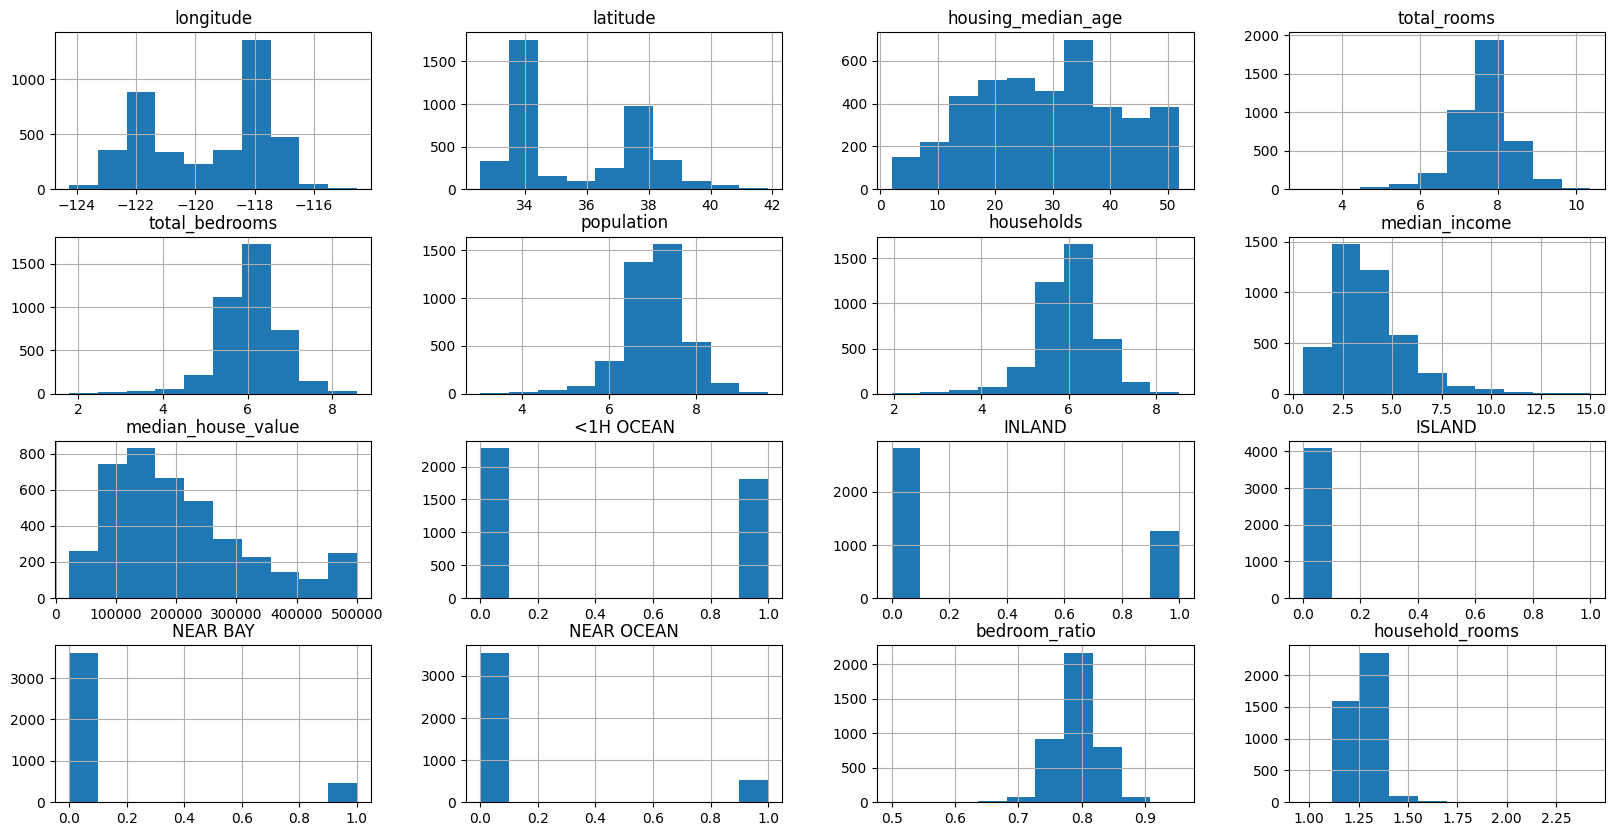

In [ ]:
test_data.hist(figsize=(20,10))

In [ ]:
test_data.shape

(4087, 16)

In [ ]:
x_test_s= scaler.transform(x_test)
x_test.columns = x_train.columns
print(x_train.shape)
print(x_test.shape)


(16346, 15)
(4087, 15)


In [ ]:
print(x_train.columns)
print(x_test.columns)


Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       '<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN',
       'bedroom_ratio', 'household_rooms'],
      dtype='object')
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       '<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN',
       'bedroom_ratio', 'household_rooms'],
      dtype='object')


In [ ]:
best_score = reg.score(x_test_s,y_test)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
forest = RandomForestRegressor()
forest.fit (x_train_s,y_train)

RandomForestRegressor()

In [ ]:
forest.score(x_test_s,y_test)

0.8172008456154246

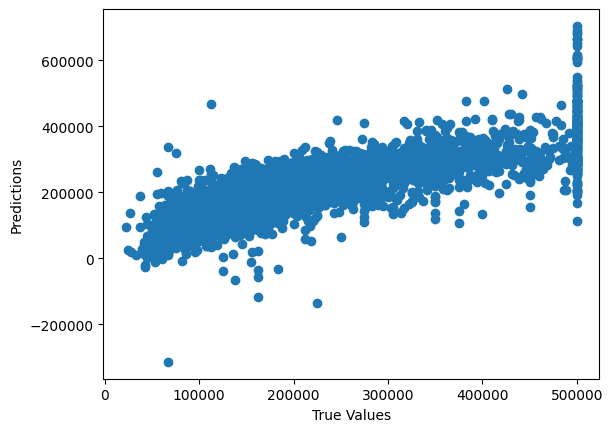

In [ ]:
predictions = reg.predict(x_test_s)
plt.scatter(y_test, predictions)
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.show()



Length of y_test: 4087
Length of predictions: 4087
Length of residuals: 4087


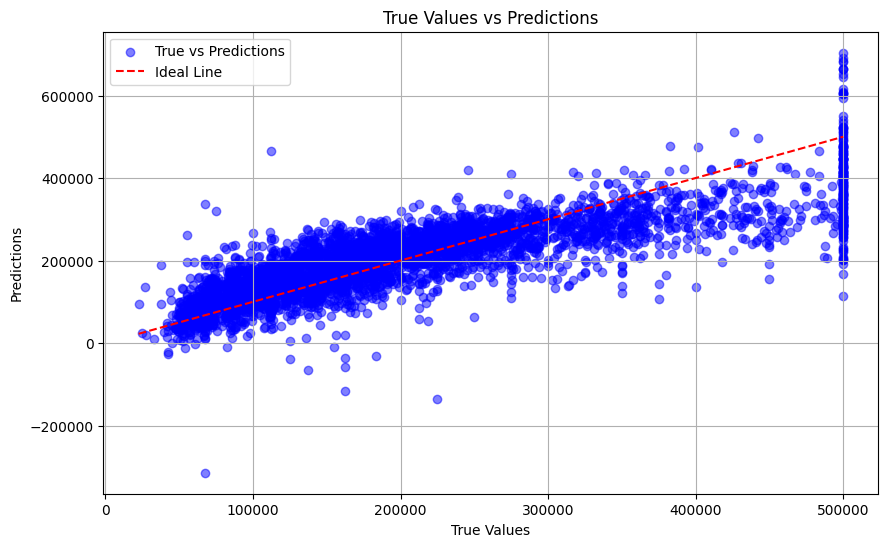

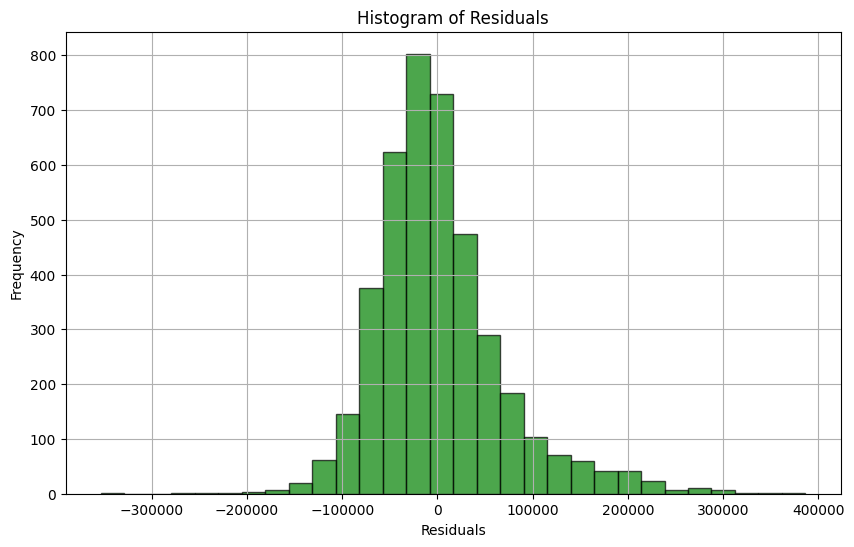

In [ ]:
import matplotlib.pyplot as plt

# Make predictions on the standardized test set
predictions = reg.predict(x_test_s)

# Check the lengths of arrays
print("Length of y_test:", len(y_test))
print("Length of predictions:", len(predictions))
residuals = y_test - predictions
print("Length of residuals:", len(residuals))

# Scatter plot of True Values vs Predictions with different colors
plt.figure(figsize=(10, 6))
plt.scatter(y_test, predictions, alpha=0.5, label='True vs Predictions', color='blue')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle='--', color='red', label='Ideal Line')  # Diagonal line for reference
plt.title('True Values vs Predictions')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.legend()
plt.grid(True)
plt.show()

# Histogram of Residuals
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, edgecolor='black', color='green', alpha=0.7)
plt.title('Histogram of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

Length of y_test: 4087
Length of predictions: 4087
Length of residuals: 4087


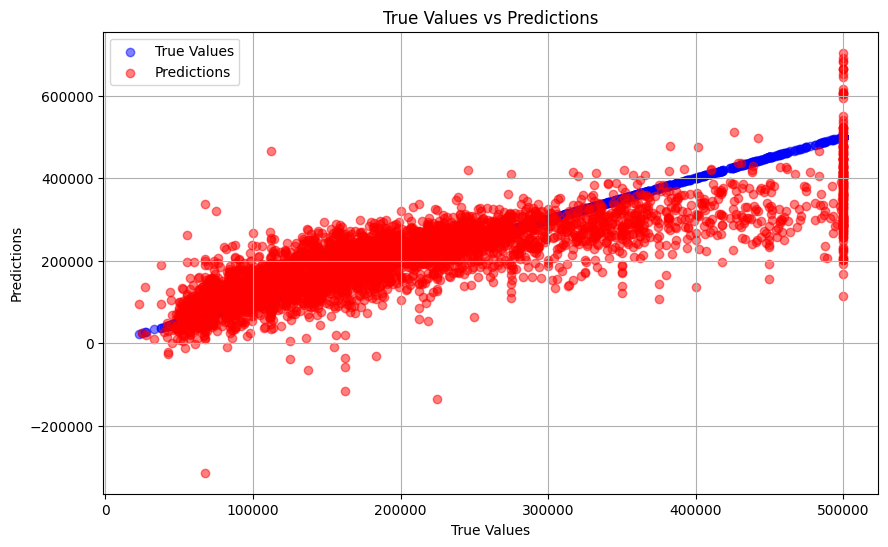

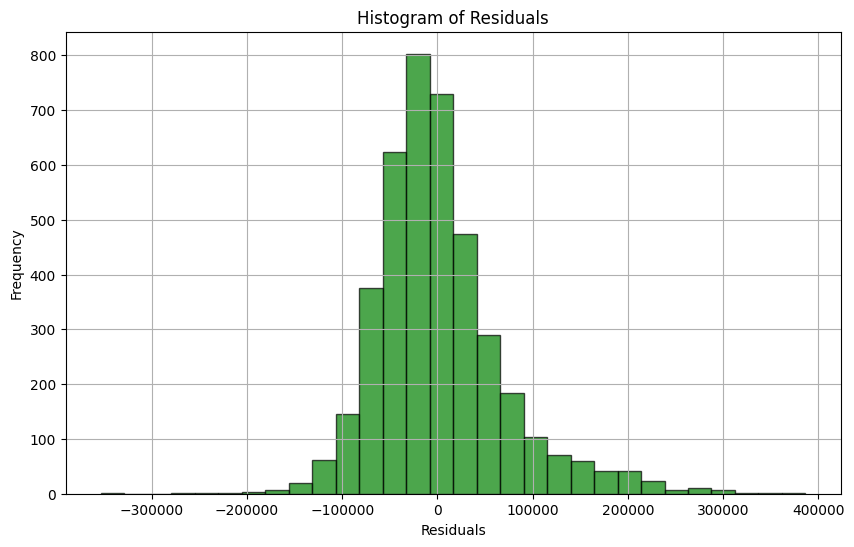

In [ ]:
import matplotlib.pyplot as plt

# Make predictions on the standardized test set
predictions = reg.predict(x_test_s)

# Check the lengths of arrays
print("Length of y_test:", len(y_test))
print("Length of predictions:", len(predictions))
print("Length of residuals:", len(residuals))

# Scatter plot of True Values vs Predictions with different colors
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_test, alpha=0.5, label='True Values', color='blue')  # True values
plt.scatter(y_test, predictions, alpha=0.5, label='Predictions', color='red')  # Predictions
plt.title('True Values vs Predictions')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.legend()
plt.grid(True)
plt.show()

# Histogram of Residuals
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, edgecolor='black', color='green', alpha=0.7)
plt.title('Histogram of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


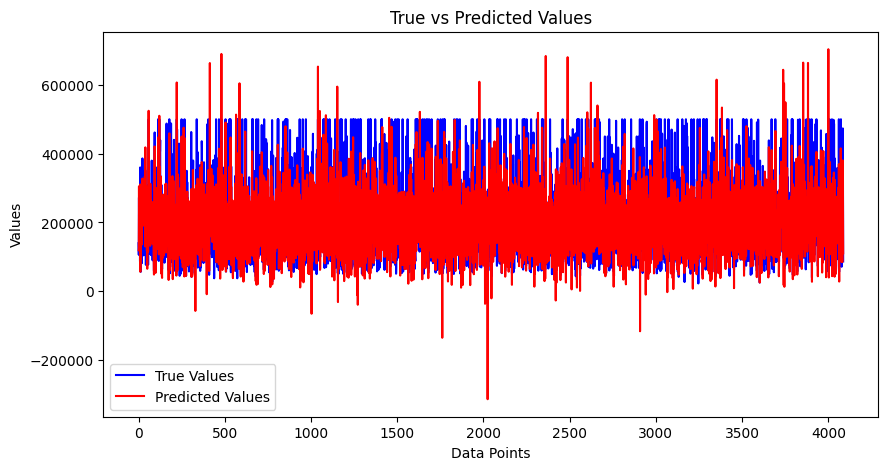

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(len(y_test)), y_test, label='True Values', color='blue')
plt.plot(range(len(predictions)), predictions, label='Predicted Values', color='red')
plt.xlabel('Data Points')
plt.ylabel('Values')
plt.title('True vs Predicted Values')
plt.legend()
plt.show()


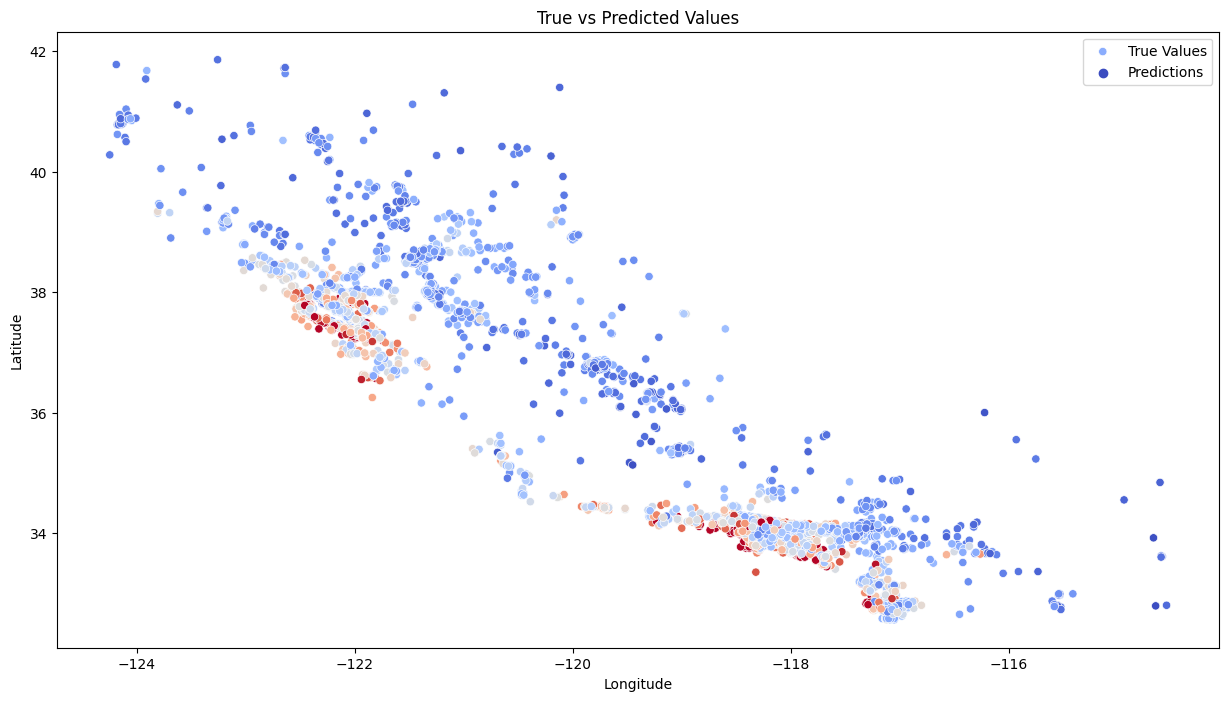

In [ ]:
plt.figure(figsize=(15,8))
scatter_plot = sns.scatterplot(x='longitude', y='latitude', data=test_data, hue='median_house_value', palette='coolwarm', legend='full')
scatter_plot.set_title('True vs Predicted Values')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(labels=['True Values', 'Predictions'], loc='upper right')


In [ ]:
import pandas as pd

# Make predictions on the standardized testing set
predictions = reg.predict(x_test_s)

# Create a DataFrame to store the true and predicted values
prediction_table = pd.DataFrame({'True_Values': y_test, 'Predictions': predictions})

# Display the table
print(prediction_table)


       True_Values    Predictions
4464      139500.0  118874.119022
4847      105800.0  126152.887077
18458     272400.0  304914.887777
15021     166300.0  209493.810067
14994     137000.0  212634.994378
...            ...            ...
7453      171800.0  245016.975908
15941     236200.0  231927.884477
18377     473400.0  380230.234188
8785      271100.0  265547.695049
18915      86400.0  110491.297482

[4087 rows x 2 columns]


In [ ]:
import plotly.express as px

# Create an interactive scatter plot with true and predicted values
fig = px.scatter(test_data, x='longitude', y='latitude', color='median_house_value',
                 size='median_house_value', hover_data=['median_house_value'],
                 color_continuous_scale='RdBu', size_max=15,
                 title='True vs Predicted Values', labels={'latitude': 'Latitude', 'longitude': 'Longitude', 'median_house_value': 'House Value'})

# Show the interactive plot
plt.figure(figsize=(20, 10))
fig.show()

<Figure size 2000x1000 with 0 Axes>

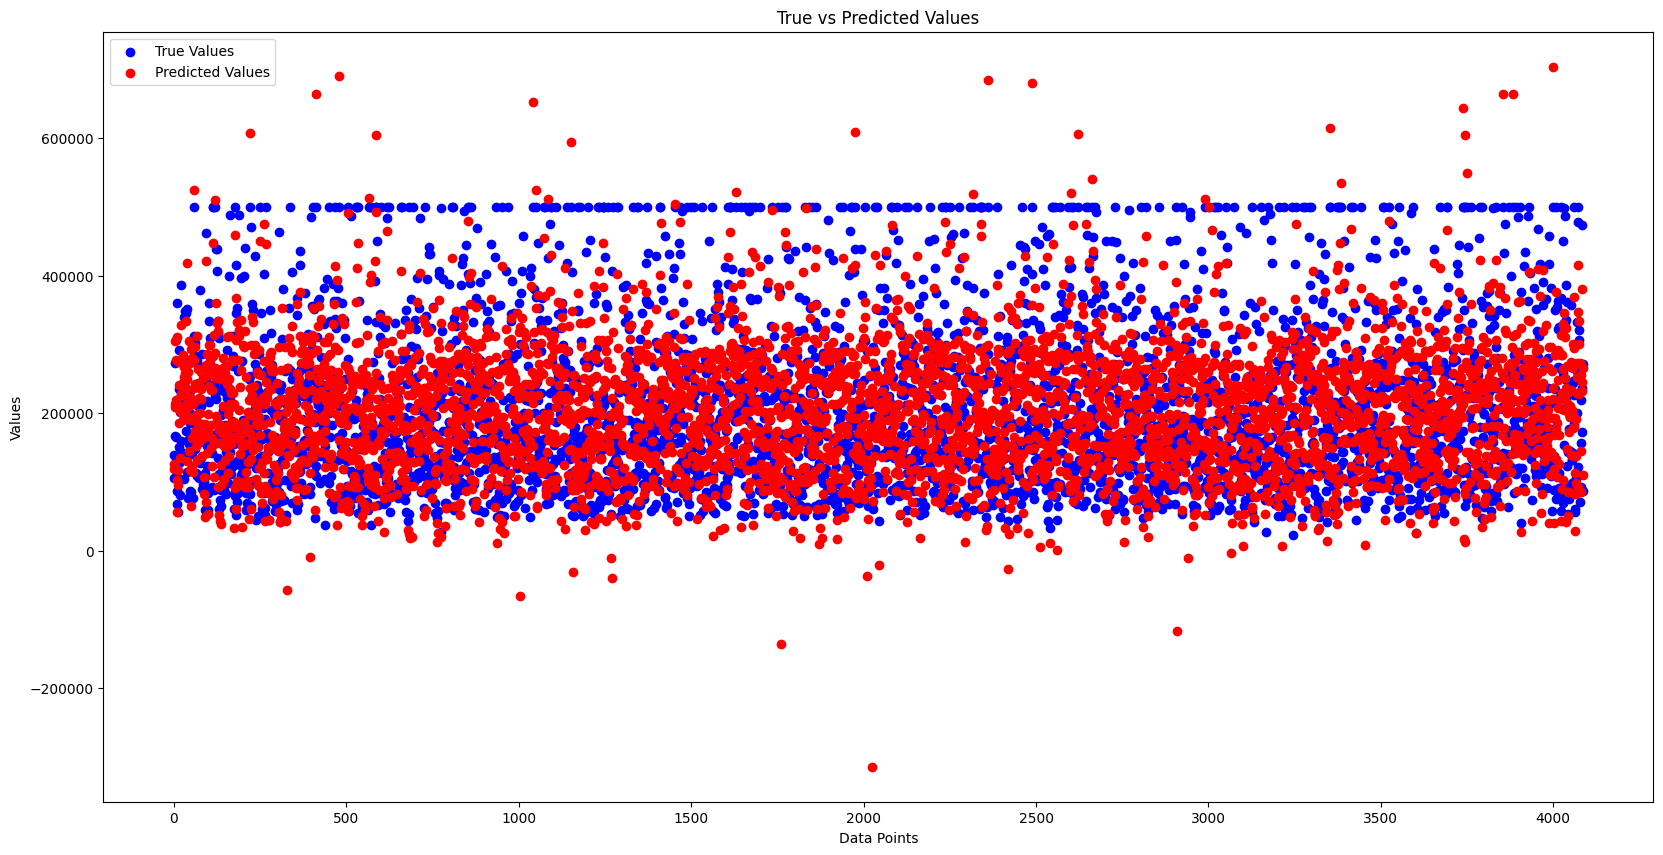

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plt.scatter(range(len(y_test)), y_test, label='True Values', color='blue')
plt.scatter(range(len(predictions)), predictions, label='Predicted Values', color='red')
plt.xlabel('Data Points')
plt.ylabel('Values')
plt.title('True vs Predicted Values')
plt.legend()
plt.show()

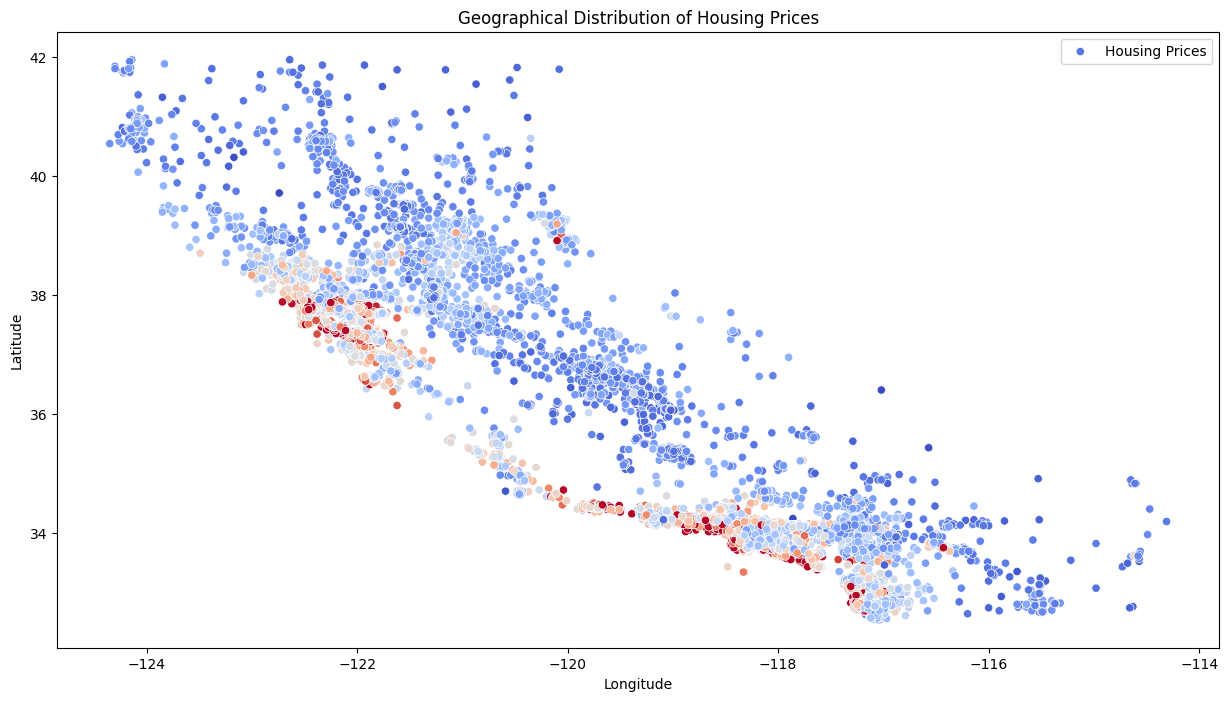

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15,8))
scatter_plot = sns.scatterplot(x='longitude', y='latitude', data=train_data, hue='median_house_value', palette='coolwarm', legend='full')
scatter_plot.set_title('Geographical Distribution of Housing Prices')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(labels=['Housing Prices'], loc='upper right')
plt.show()

In [ ]:

fig.update_traces(marker={'size': 10})

In [ ]:
prediction_table.to_csv('prediction_table.csv', index=False)
